# Báo cáo eval: đợt planning 06/11 (chạy ngày 08/11/2026)

**Câu hỏi:** sau đợt thay đổi lớn (Prompt Registry, bố cục prompt v2, hot window ảnh, Artifact Resolver, Essay Mode gộp router), hệ thống có **vẫn trả lời đúng**, và có **nhanh/rẻ hơn nhờ KV cache** như thiết kế không?

**Trả lời ngắn:**
1. **Chất lượng giữ vững.** QA golden 8 câu: mean 94%, pass 100%. Essay 3 đề QNX: đạt cả 3. Chọn artifact: 33/33 case.
2. **Cache hoạt động ở đúng chỗ thiết kế nhắm tới.** System tĩnh ① (khoảng 4k token) được dùng chung giữa **các hội thoại khác nhau**. Ngay sau khi `/c4` tạo artifact mới, bố cục **v1 mất sạch cache (0 token)** còn **v2 vẫn giữ khoảng 4.080 token**.
3. **Giới hạn thật của cache Gemini:** hit tăng theo bậc khoảng 2k token và **trễ 1 lượt**, nên history ngắn gần như không được cache. Hot window (K=2) chưa tạo khác biệt đo được với hội thoại 5 lượt.
4. **Sự cố thật trong lúc đo:** Gemini trả 503 khoảng 4 phút. Retry, circuit breaker và fallback chạy đúng, và lộ ra **một model fallback đã bị Google gỡ** (`gemini-2.5-flash-lite`, đã bỏ khỏi default).

> Môi trường: harness local trỏ **dev** (Neon dev branch, R2 `cter-dev`, Pinecone `cter-develop-uat`). Model `gemini-3.1-flash-lite`. Vault tạm 10 file Week-01/02 (195 KB), đã xoá sau khi đo. Dữ liệu thô: `evals/results/`, `evals/reports/data/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import report_lib as R
R.style()
pd.set_option('display.max_colwidth', 60)
qa, qa_summary = R.qa_results()
essay, essay_summary = R.essay_results()
refs = R.reference_results()
runs = R.cache_runs()
incident = R.incident()

## 1. Tổng quan

In [2]:
plain = refs[~refs['ambiguousExpected']]
amb = refs[refs['ambiguousExpected']]
judge_cols = [c for c in essay.columns if c.startswith('judge_')]
kpi = pd.DataFrame([
    ('QA golden (rule)', f"{R.pct(qa_summary['meanScore'])} · pass {R.pct(qa_summary['passRate'])} · judge {R.pct(qa['judge'].mean())}", f"{len(qa)} case"),
    ('Essay Mode (rule)', f"{R.pct(essay_summary['meanScore'])} · judge {essay[judge_cols].mean().mean():.1f}/5", f"{len(essay)} case"),
    ('Chọn artifact (offline)', f"{R.pct(plain['ok'].mean())} · mơ hồ {R.pct(amb['ok'].mean())}", f"{len(refs)} case"),
    ('Cache giữa hội thoại (median)', f"{R.pct((qa['cached'] / qa['input']).median())}", 'mỗi câu QA là 1 hội thoại mới'),
    ('Thời gian trả lời QA', f"p50 {qa['total_s'].median():.1f}s · max {qa['total_s'].max():.1f}s", f"{len(qa)} case"),
], columns=['Hạng mục', 'Kết quả', 'Cỡ mẫu'])
kpi.style.hide(axis='index')

Hạng mục,Kết quả,Cỡ mẫu
QA golden (rule),94% · pass 100% · judge 99%,8 case
Essay Mode (rule),100% · judge 5.0/5,3 case
Chọn artifact (offline),100% · mơ hồ 100%,33 case
Cache giữa hội thoại (median),75%,mỗi câu QA là 1 hội thoại mới
Thời gian trả lời QA,p50 4.4s · max 6.9s,8 case


## 2. Chất lượng câu trả lời QA

Mỗi câu golden có danh sách ý bắt buộc (`expected_points`). Điểm rule = tỉ lệ ý xuất hiện, có trừ điểm khi còn mục References hoặc chứa ký hiệu cấm. Judge là chính model đó chấm 0–10.

Hai lần chạy cùng prompt, cùng model cho kết quả **khác nhau ở 2/8 câu** (T01 71%→100%, T05 60%→80%). Đây là độ dao động tự nhiên của model, nên **đừng kết luận từ chênh lệch một câu**: so baseline phải nhìn mean và nhiều lần chạy.

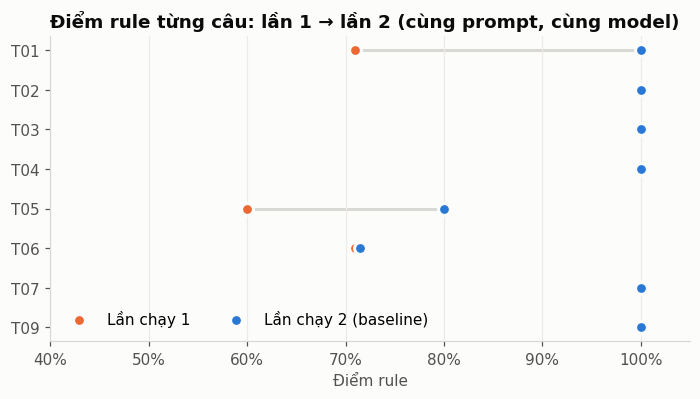

In [3]:
fig = R.plot_qa_runs(qa, 'vi'); fig.axes[0].set_title('Điểm rule từng câu: lần 1 → lần 2 (cùng prompt, cùng model)'); plt.show()

In [4]:
qa[['id', 'score', 'judge', 'missing', 'total_s']].rename(columns={'score': 'rule', 'missing': 'ý thiếu', 'total_s': 'giây'})

,id,rule,judge,ý thiếu,giây
0,T01,1.000000,1.0,,5.997
1,T02,1.000000,1.0,,4.983
2,T03,1.000000,1.0,,6.870
3,T04,1.000000,1.0,,6.722
4,T05,0.800000,0.9,*n,3.140
5,T06,0.714286,1.0,"uname, kill",3.247
6,T07,1.000000,1.0,,3.814
7,T09,1.000000,1.0,,3.294


**Nhận xét:** ý hay thiếu là các chi tiết liệt kê (`uname`, `kill` trong T06, ký hiệu `*n` trong T05), không phải sai kiến thức. Judge cho 90–100%. Judge là cùng một model nên dễ dễ dãi; xem phần giới hạn ở cuối.

## 3. Độ trễ: thời gian đi đâu

Tổng thời gian mỗi câu = truy xuất (embedding + Pinecone + BM25) + model sinh câu trả lời.

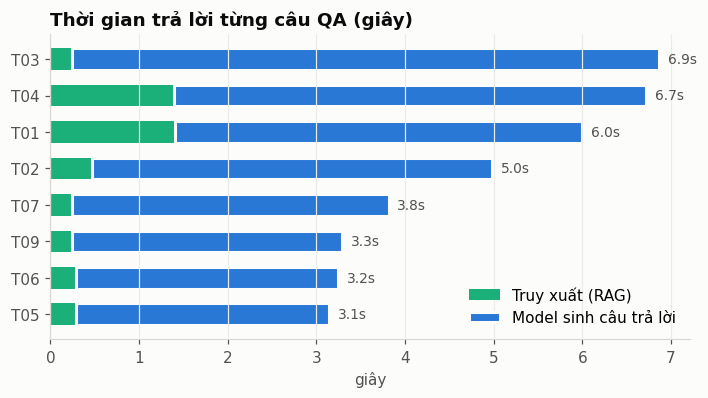

In [5]:
fig = R.plot_qa_latency(qa, 'vi'); fig.axes[0].set_title('Thời gian trả lời từng câu QA (giây)'); plt.show()

Phần lớn thời gian là **model**. Truy xuất chỉ từ 0,25 đến 1,4 s: chậm khi embedding chưa warm, sau đó còn khoảng 0,25 s. Mọi câu xong trong **dưới 7 s**, xa mức deadline 90 s.

## 4. KV cache: phần dùng chung giữa các hội thoại

Mỗi câu QA được gửi như **một hội thoại mới**, không có history. Nếu bố cục v2 làm đúng việc, phần system tĩnh ① phải **giống hệt byte** giữa các câu, và Gemini sẽ đọc nó từ cache.

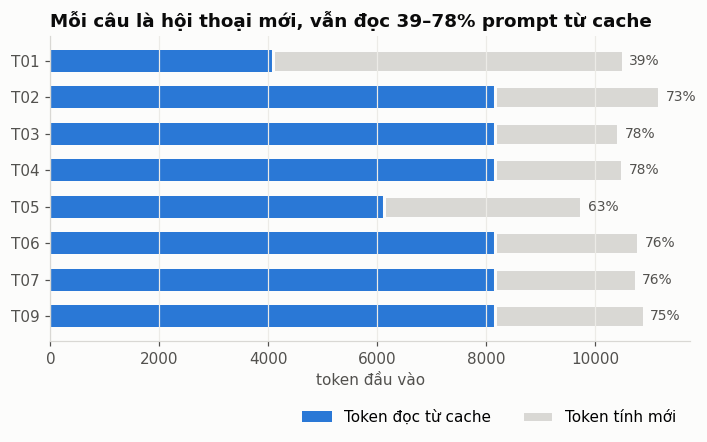

In [6]:
fig = R.plot_cross_conversation_cache(qa, 'vi'); fig.axes[0].set_title('Mỗi câu là hội thoại mới, vẫn đọc 39–78% prompt từ cache'); plt.show()

- 6/8 câu đọc khoảng **8.166 token** từ cache, tức khoảng 75% prompt. Con số này lớn hơn riêng system tĩnh ① (khoảng 4k token), nghĩa là còn một phần nội dung khác cũng giống hệt giữa các câu. Chưa xác định chính xác là phần nào; cần đo thêm.
- T01 (câu đầu tiên sau khi khởi động) chỉ được 4.082 token: cache còn **lạnh**. T05 được 6.122 token: Gemini cache theo **khối khoảng 2k token**, và hit là *best-effort*.
- Ý nghĩa: với nhiều user, mỗi request mới đều được hưởng phần ① đã cache sẵn, nên **TTFT giảm ngay từ lượt đầu**.

## 5. KV cache theo lượt: v1 vs v2, hot window

Thí nghiệm `npm run eval:cache`: 3 cấu hình, cùng một kịch bản. Kịch bản **c4** gồm: chat → `/c4` vẽ diagram → 3 câu hỏi về hình. Kịch bản **long** gồm 6 câu trả lời dài. Khởi động lại harness giữa các cấu hình.

| Cấu hình | `PROMPT_CACHE_LAYOUT` | `CONTEXT_HOT_WINDOW_TURNS` |
|---|---|---|
| v2-k2 (mặc định mới) | v2 | 2 |
| v2-k0 | v2 | 0 |
| v1-k0 (rollback) | v1 | 0 |

In [7]:
rows = []
for run in runs:
    for _, t in run.turns.iterrows():
        rows.append({'config': run.config, 'run': run.label, 'scenario': run.scenario, 'turn': t['turn'], 'kind': t['kind'],
                     'ok': t['ok'], 'input': t['inputTokens'], 'cached': t['cachedTokens'],
                     'ttft_s': None if pd.isna(t['ttftMs']) else round(t['ttftMs'] / 1000, 2)})
cache = pd.DataFrame(rows)
pivot = cache[(cache['scenario'] == 'c4') & cache['ok'] & (cache['kind'] == 'chat')].pivot_table(index='turn', columns='run', values='cached', aggfunc='first')
pivot

run,v1-k0,v2-k0,v2-k2,v2-k2-r2
turn,,,,
1,0.0,4083.0,4083.0,8166.0
3,0.0,4080.0,4079.0,4079.0
4,4075.0,4076.0,4076.0,4076.0
5,4074.0,4074.0,4074.0,4074.0


**Điểm mấu chốt nằm ở lượt 3**, câu hỏi đầu tiên sau khi `/c4` tạo artifact:
- **v1: 0 token cache.** Registry artifact nằm trong system prompt, nên artifact mới làm đổi system và cache phía sau mất hết.
- **v2: khoảng 4.080 token cache.** Registry nằm ở tin cuối, nên system ① vẫn giống hệt byte.

Đây đúng là vấn đề note 18 mô tả, và bố cục v2 sửa được nó.

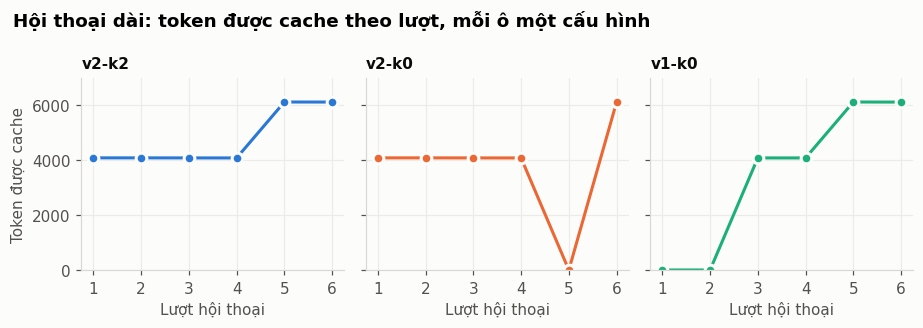

In [8]:
fig = R.plot_cache_turns(runs, 'long', 'vi'); fig.suptitle('Hội thoại dài: token được cache theo lượt, mỗi ô một cấu hình', x=0.02, ha='left', fontweight='bold'); fig.tight_layout(); plt.show()

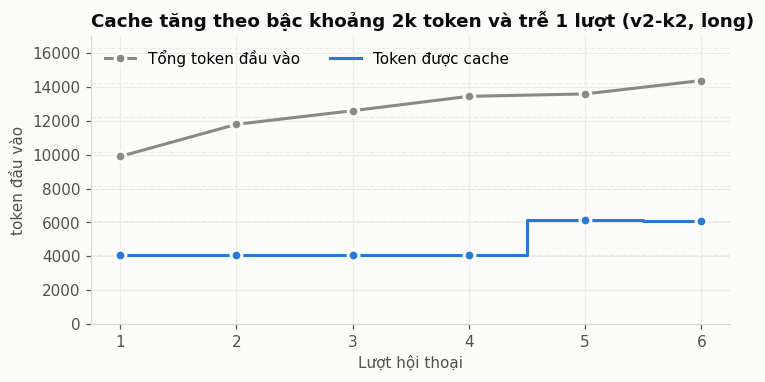

In [9]:
long_run = [r for r in runs if r.label == 'v2-k2-long'][0]
fig = R.plot_cache_blocks(long_run, 'vi'); fig.axes[0].set_title('Cache tăng theo bậc khoảng 2k token và trễ 1 lượt (v2-k2, long)'); plt.show()

**Vì sao history ít được cache?**
1. **Trễ 1 lượt.** Request lượt *n* có đuôi là câu hỏi + RAG của lượt *n*. Ở lượt *n+1*, lượt *n* chỉ còn text câu hỏi, không còn RAG. Phần prefix trùng với request trước vì vậy chỉ kéo tới **hết lượt n−1**.
2. **Bậc khoảng 2k token.** Gemini báo `cachedTokens` theo bội của khoảng 2.037 token. History phải dài thêm khoảng 2k token mới lên một bậc. Trong kịch bản long, bậc mới chỉ xuất hiện ở lượt 5 (6.114). Riêng v2-k0 ở lượt 5 bị miss hẳn (0), rồi lượt 6 lại hit: cache của Gemini là best-effort.
3. **Hot window K=2 so với K=0:** không thấy khác biệt. Ảnh diagram C4 khá nhỏ, nằm dưới một bậc, và window trượt mỗi lượt. Lợi ích của hot window sẽ hiện ra với **ảnh lớn hoặc nhiều ảnh**, như đề bài chụp màn hình. Cần đo thêm trước khi kết luận.
4. v1 ở lượt 1–2 có cache 0 vì đó là request v1 đầu tiên sau khởi động: chưa ai làm ấm prefix v1. Trên prod với nhiều user thì lượt đầu của v1 cũng sẽ có cache. Khác biệt **thật** giữa v1 và v2 nằm ở lượt ngay sau khi có artifact mới.

## 6. Essay Mode: phân tích đề gộp vào router

Đề tự luận có số điểm → số từ mục tiêu (điểm × 175). Kiểm tra: độ dài nằm trong ±25%, mọi trích dẫn `[c:id]` trỏ đúng chunk, phủ đủ các ý, và có trích nguồn đúng tuần học.

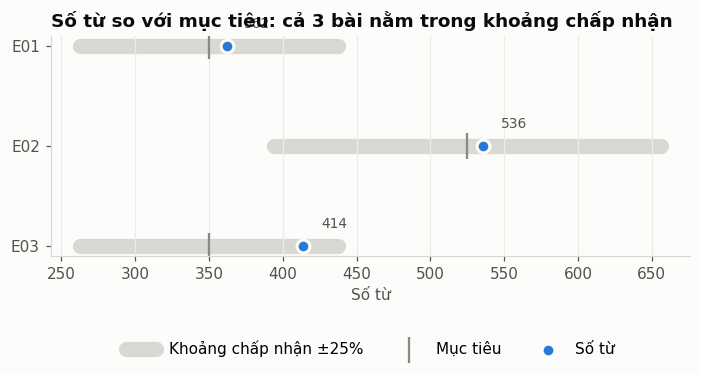

In [10]:
fig = R.plot_essay_length(essay, 'vi'); fig.axes[0].set_title('Số từ so với mục tiêu: cả 3 bài nằm trong khoảng chấp nhận'); plt.show()

In [11]:
essay[['id', 'score', 'words', 'target', 'citations_ok', 'coverage', 'llm_calls', 'total_s', 'input', 'cached']]

,id,score,words,target,citations_ok,coverage,llm_calls,total_s,input,cached
0,E01,1,362,350,True,1,2,9.738,11781,0
1,E02,1,536,525,True,1,2,10.133,15334,0
2,E03,1,414,350,True,1,2,10.680,13823,0


- `llm_calls = 2`: **1 lần gọi aux chung** (router + phân tích đề, trước đây là 2 lần riêng) và **1 lần viết**. Thiết kế đạt mục tiêu ≤ 1 aux.
- Judge cho 5/5 ở mọi tiêu chí: **hiệu ứng trần**. Judge cùng model, nên không phân biệt được chất lượng. Lần sau nên dùng model judge mạnh hơn (`EVAL_JUDGE_MODEL`).
- ⚠️ **Phát hiện:** essay có `cached = 0`, dù prompt dài 12–15k token. Prompt essay (rubric + skill writer) không có prefix ổn định như chat. Đây là cơ hội tối ưu tiếp theo: đưa phần tĩnh của skill essay lên đầu.

## 7. Chọn artifact (Artifact Resolver, offline)

33 case trên hội thoại giả, chỉ có metadata, chạy bằng rule và không tốn token: 1 design, 2 hệ thống, nhiều version, cách diễn đạt khác nhau, câu mơ hồ, câu âm tính…

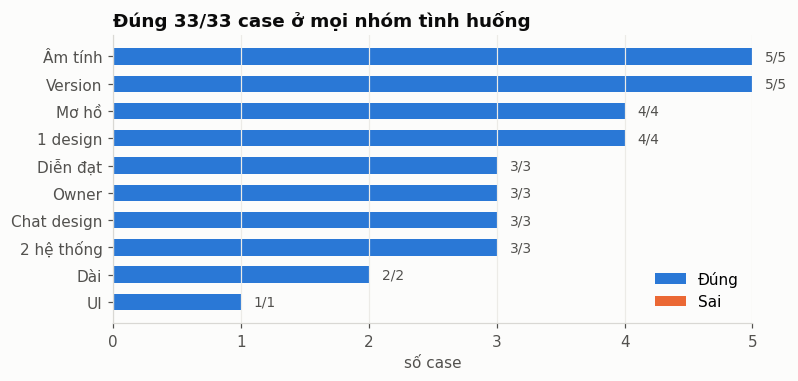

In [12]:
fig = R.plot_reference_groups(refs, 'vi'); fig.axes[0].set_title('Đúng 33/33 case ở mọi nhóm tình huống'); plt.show()

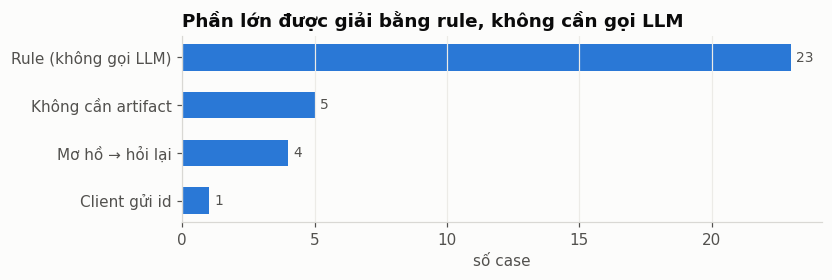

In [13]:
fig = R.plot_reference_sources(refs, 'vi'); fig.axes[0].set_title('Phần lớn được giải bằng rule, không cần gọi LLM'); plt.show()

> ⚠️ Rule được tinh chỉnh **trên chính bộ case này**, nên 100% là cận trên. Với câu hỏi thật, tỉ lệ có thể thấp hơn. Theo dõi `resolved_refs` trong monitoring (trang Chats).

## 8. Sự cố thật: Gemini 503 trong lúc đo

Khoảng 07:51–07:55, Gemini trả **503 "high demand"**. Đây là dữ liệu thật về cơ chế resilience của note 07:

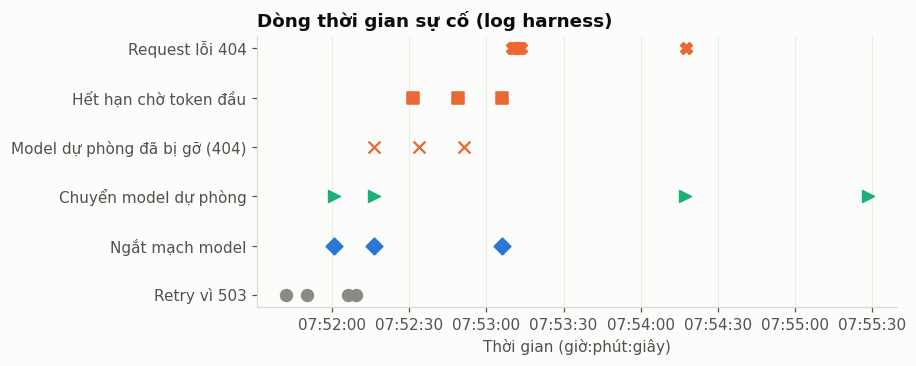

In [14]:
fig = R.plot_incident(incident, 'vi'); fig.axes[0].set_title('Dòng thời gian sự cố (log harness)'); plt.show()

- **Retry 503** tối đa 2 lần (`MAX_RETRY_COUNT=2`). Sau đó **ngắt mạch** model 120 s và chuyển sang model kế tiếp. Không còn treo hơn 5 phút như khi retry 12 lần.
- Chuỗi fallback có `gemini-2.5-flash-lite`, model Google **đã gỡ** (404). Mỗi request phí một lượt thử. **Đã bỏ khỏi default trong code và `.env.example`.** `.env` dev và Render prod vẫn phải sửa tay `MODEL_FALLBACK_GEMINI`.
- Model cuối là OpenRouter `gemini-3.5-flash`, cũng không ra token đầu trong 15 s. Khi cả nhà cung cấp quá tải thì request vẫn lỗi, nhưng **lỗi nhanh**, không treo.

## 9. Kết luận và việc tiếp theo

| # | Kết luận | Hành động |
|---|---|---|
| 1 | Chất lượng QA/Essay/Resolver đạt | Đã lưu `evals/results/baseline.json` (mean 94%). Mọi thay đổi prompt sau này phải ≥ baseline |
| 2 | v2 giữ cache khi có artifact mới, v1 thì không | Giữ `PROMPT_CACHE_LAYOUT=v2` |
| 3 | History ngắn gần như không được cache (bậc 2k, trễ 1 lượt) | Không kỳ vọng quá vào cache history với chat ngắn. Lợi ích chính là ① dùng chung |
| 4 | Hot window chưa có khác biệt đo được | Giữ K=2 nhưng đo lại với đề bài nhiều ảnh lớn. Nếu tốn quota mà không lợi thì đặt `CONTEXT_HOT_WINDOW_TURNS=0` |
| 5 | Essay không được cache | Việc tối ưu tiếp theo: prefix tĩnh cho prompt essay |
| 6 | Fallback có model đã gỡ | Sửa `MODEL_FALLBACK_GEMINI` ở `.env` dev và Render |

**Giới hạn của báo cáo:**
- Cỡ mẫu nhỏ: 8 + 3 + 33 case, mỗi cấu hình cache chạy 1–2 lần.
- Chỉ một model (Gemini flash-lite). Judge là cùng model.
- Vault chỉ có Week-01/02. Đề essay môn Software Testing và Usability chưa đo vì vault dev không có tài liệu.
- Cache của Gemini là best-effort, và có thời điểm Gemini đang quá tải.

**Chạy lại báo cáo:** chạy các lệnh eval (xem `planning/.../handoff/05-system-prompt-guide.md` §5), rồi *Run All* notebook này.